# Part 8 — Business Recommendation
## Ontario Winters and El Niño

**For:** municipal winter-maintenance planners in Ontario, and the project team
**Question asked:** *Before a winter begins, can we tell a municipality whether it is heading for a mild winter, so that salt, plough and overtime budgets can be set with better information?*

**Short answer:** not for an individual winter. But the record does support one narrow, usable statement, and it is not the one a model produces.

This notebook contains no modelling. It is what the analysis implies, what it does not, and what a planner should do with it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 130)

pred = pd.read_csv('winter_predictions.csv')
metrics = pd.read_csv('winter_metrics.csv', index_col=0)['value']
kpis = pd.read_csv('../../data/processed/winter_kpis.csv')

print(f'{len(pred)} location-winters, each predicted by a model that never saw that winter')
print(f'{pred["winter_year"].nunique()} distinct winters | {pred["city_name"].nunique()} locations')

247 location-winters, each predicted by a model that never saw that winter
44 distinct winters | 6 locations


---
## 1. The key finding

> **The model does not beat assuming every winter will be normal — it is 0.8 percentage points *less* accurate. But the historical record still contains one usable signal: in the five strong El Niño winters since 1982, roughly seven out of ten Ontario location-winters came in at least 1 °C above normal, and the effect was concentrated in the north.**

Two separate claims, and the difference between them is the whole notebook. The first is about a model. The second is about a base rate.

In [2]:
print(f'{"":34} {"Accuracy":>10}  {"AUC":>6}')
print(f'{"Assume no winter is ever mild":34} {metrics["baseline_accuracy"]:>10.1%}  {0.5:>6.3f}')
print(f'{"Our model":34} {metrics["accuracy"]:>10.1%}  {metrics["roc_auc"]:>6.3f}')
print()
print(f'Precision of the model\'s mild calls: {metrics["precision"]:.1%}')
print(f'  — wrong more often than right.')
print()
print(f'Based on {int(metrics["n_rows"])} location-winters from {int(metrics["n_winters"])} distinct winters.')

                                     Accuracy     AUC
Assume no winter is ever mild           69.2%   0.500
Our model                               68.4%   0.609

Precision of the model's mild calls: 47.4%
  — wrong more often than right.

Based on 247 location-winters from 44 distinct winters.


**The model ranks slightly better than chance (AUC 0.61) and labels slightly worse than doing nothing.** Both are true, and neither supports putting it in front of a budget committee.

## 2. The evidence that does hold up

Set the model aside and look at the base rates directly.

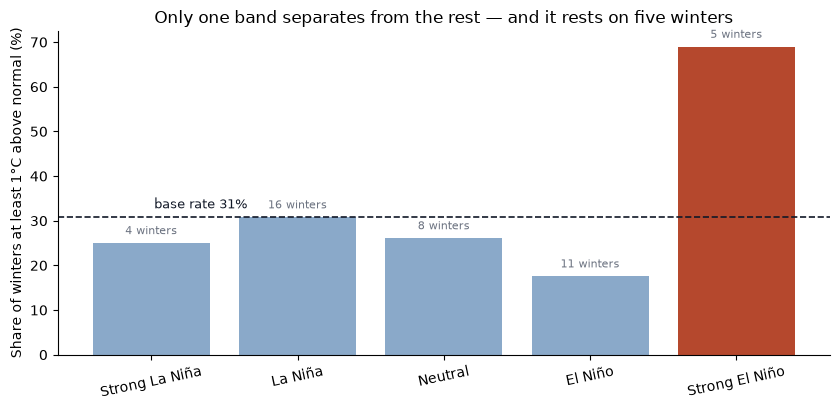

,Location_Winters,Distinct_Winters,Mild_Rate
ENSO_Band,,,
Strong La Niña,24,4,25.0%
La Niña,91,16,30.8%
Neutral,46,8,26.1%
El Niño,57,11,17.5%
Strong El Niño,29,5,69.0%


In [3]:
band_order = ['Strong La Niña', 'La Niña', 'Neutral', 'El Niño', 'Strong El Niño']
bands = (pred.groupby('ENSO_Band')
            .agg(Location_Winters=('Actual_Mild', 'size'),
                 Distinct_Winters=('winter_year', 'nunique'),
                 Mild_Rate=('Actual_Mild', 'mean'))
            .reindex([b for b in band_order if b in pred['ENSO_Band'].unique()]))

base = pred['Actual_Mild'].mean()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = ['#b5482d' if b == 'Strong El Niño' else '#8aa9c9' for b in bands.index]
ax.bar(bands.index, bands['Mild_Rate'] * 100, color=colors)
ax.axhline(base * 100, color='#111827', linestyle='--', linewidth=1.2)
ax.text(.02, base * 100 + 2, f'base rate {base:.0%}', fontsize=9, color='#111827')
for i, (rate, w) in enumerate(zip(bands['Mild_Rate'], bands['Distinct_Winters'])):
    ax.text(i, rate * 100 + 2, f'{w} winters', ha='center', fontsize=8, color='#6b7280')
ax.set(ylabel='Share of winters at least 1°C above normal (%)',
       title='Only one band separates from the rest — and it rests on five winters')
ax.tick_params(axis='x', rotation=12)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('../../reports/figures/ml_mild_rate_by_enso_band.png', dpi=160, bbox_inches='tight')
plt.show()

out = bands.copy()
out['Mild_Rate'] = (out['Mild_Rate'] * 100).round(1).astype(str) + '%'
out

**The relationship is a step, not a slope.** A moderate El Niño winter — index between +0.5 and +1.5 — was mild *less* often than a neutral winter. Nothing happens until the index clears +1.5.

So "an El Niño is coming" is not, on this record, a planning input at all. "A *strong* El Niño is coming" is a different statement — and it rests on five winters.

### Where the effect lands

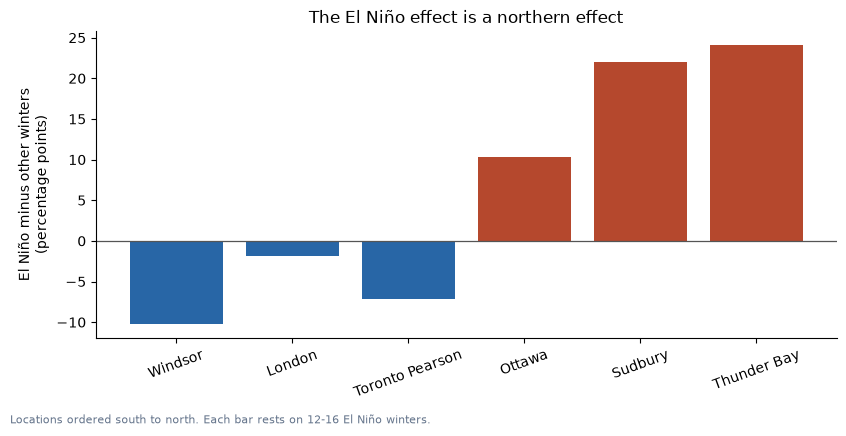

,Location,Latitude,El Niño,Other,Difference,n
0,Windsor,42.28,0.17,0.27,-0.10,12
1,London,43.03,0.27,0.29,-0.02,15
2,Toronto Pearson,43.68,0.25,0.32,-0.07,16
3,Ottawa,45.32,0.40,0.30,0.10,15
4,Sudbury,46.63,0.50,0.28,0.22,14
5,Thunder Bay,48.37,0.50,0.26,0.24,14


In [4]:
rows = []
for city, block in pred.groupby('city_name'):
    el_nino = block[block['ENSO_Class'] == 'El Nino']['Actual_Mild']
    other = block[block['ENSO_Class'] != 'El Nino']['Actual_Mild']
    rows.append({'Location': city, 'Latitude': block['latitude_approx'].iloc[0],
                 'El Niño': el_nino.mean(), 'Other': other.mean(),
                 'Difference': el_nino.mean() - other.mean(), 'n': len(el_nino)})
gradient = pd.DataFrame(rows).sort_values('Latitude').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(gradient['Location'], gradient['Difference'] * 100,
       color=['#b5482d' if d > 0 else '#2866a6' for d in gradient['Difference']])
ax.axhline(0, color='#555', linewidth=.9)
ax.set(ylabel='El Niño minus other winters\n(percentage points)',
       title='The El Niño effect is a northern effect')
ax.tick_params(axis='x', rotation=20)
ax.spines[['top', 'right']].set_visible(False)
fig.text(.01, -.02, 'Locations ordered south to north. Each bar rests on 12-16 El Niño winters.',
         fontsize=8, color='#64748b')
fig.tight_layout()
fig.savefig('../../reports/figures/ml_mild_rate_by_latitude.png', dpi=160, bbox_inches='tight')
plt.show()

gradient.round(2)

**This is the project's BQ4, answered.** The El Niño effect rises steadily with latitude: slightly negative in the far southwest, clearly positive at Sudbury and Thunder Bay.

A single Ontario-wide statement about El Niño would average these together and describe nowhere in particular. Whatever a municipality does with this should depend on where it is.

## 3. The thing that would be most expensive to get wrong

A milder winter is not a winter without cold snaps. If a planner reads "mild" as "fewer extreme-cold days to prepare for", this is the table that should stop them.

In [5]:
cold = kpis[kpis['cold_days_pass']].copy()
cold['Strong_El_Nino'] = cold['roni_djf'] >= 1.5

north = cold[(cold['Strong_El_Nino']) & (cold['city_name'].isin(['Thunder Bay', 'Sudbury']))]
print('Days at or below -20°C during STRONG El Niño winters, northern stations:')
print(north[['city_name', 'winter_year', 'days_below_m20', 'temp_anomaly']]
      .sort_values(['city_name', 'winter_year']).round(1).to_string(index=False))
print()
for city in ['Thunder Bay', 'Sudbury']:
    typical = cold[cold['city_name'] == city]['days_below_m20'].median()
    print(f'{city}: median across all winters = {typical:.0f} extreme-cold days')

Days at or below -20°C during STRONG El Niño winters, northern stations:
  city_name  winter_year  days_below_m20  temp_anomaly
    Sudbury         1983            24.0           1.8
    Sudbury         1987            19.0           1.9
    Sudbury         1992            31.0          -0.7
    Sudbury         2016            18.0           2.8
Thunder Bay         1983            24.0           2.5
Thunder Bay         1987            17.0           3.6
Thunder Bay         1992            33.0           1.2

Thunder Bay: median across all winters = 37 extreme-cold days
Sudbury: median across all winters = 26 extreme-cold days


**Thunder Bay still recorded between 17 and 33 days at or below −20 °C in the strong El Niño winters** — fewer than its all-winter median of 37, but nowhere near zero. Sudbury ran 18 to 31 against a median of 26.

A mild winter in northern Ontario is still a winter with several weeks of extreme cold in it. Cold-snap readiness, equipment and crew provisions are not the line item a seasonal outlook should touch.

## 4. Back to the original question

> *Before a winter begins, can we tell a municipality whether it is heading for a mild winter?*

**Not for any individual winter.** The model is less accurate than assuming nothing, its mild calls are wrong more often than right, and a single hold-out of 11 winters produced AUCs anywhere from 0.34 to 0.77 depending on the random seed. Nothing in that supports a per-winter call.

**Partly, for a strong El Niño, in the north.** Five strong events in 44 years is not much, but the effect is large and it points the same way as the project's main analysis.

**And one methodological answer that applies beyond this project:** the Random Forest scored 0.87 when rows were split at random, and 0.55 when winters were kept whole. Had the evaluation been done the ordinary way, this notebook would be recommending a model that does not work.

## 5. Recommendation

**1. Do not use the model for budgeting.** It does not beat the assumption it would replace. This is the main recommendation and the rest are secondary to it.

**2. Use the strong-El Niño base rate as a planning *prior*, in the north only.** For Sudbury, Thunder Bay and comparable northern stations, a confirmed strong El Niño is weak evidence to lean toward the milder end of an existing planning range. It is not grounds for a new range. For Windsor, London and Toronto, the record supports no adjustment at all.

**3. Never reduce cold-snap provision.** Section 3 shows why: the strong El Niño winters still delivered weeks of extreme cold in the north. Mild in the seasonal average is not mild in the tail, and the tail is what the emergency budget is for.

**4. Treat the 2026-27 advisory carefully.** NOAA gives better than 90% confidence of a very strong El Niño. The honest statement a planner can take from this project is: *"If it verifies as strong, northern Ontario has historically leaned mild — on five prior events. Southern Ontario has not. Keep cold-snap reserves regardless."* That sentence is defensible. Anything more specific is not.

**5. Record what actually happens in 2026-27.** A sixth strong event is worth more to this analysis than any further modelling of the existing five. The single highest-value action the team can take is to measure the coming winter the same way and add it to the record.

**6. For the repository: rerun the pipeline.** `data/processed/winter_kpis.csv` still carries `enso_index = 'ONI'` and predates the switch to RONI in `python/config.py`. These notebooks derive RONI themselves to work around it, but the stored file should be regenerated so the whole project agrees on one index.

## 6. Limitations and assumptions

**The big one — five winters.**

Every usable statement in this notebook rests on the five strong El Niño winters in the record: 1983, 1987, 1992, 1998 and 2016. The project's README says the same thing in its own limitations section. Five events cannot establish a rate; they can only fail to contradict one. If the fifth behaves differently, the finding changes materially — which is a fair description of how much weight it can carry.

| Limitation | Consequence |
|---|---|
| **The DJF index is not known in advance** | The model was given the *observed* December–February value. A planner in October has a forecast of it instead. Every score here is an upper bound on what is achievable in practice. |
| **247 rows, 44 independent winters** | Six locations share each winter. The effective sample for anything ENSO-related is 44, and for strong events, five. |
| **Association, not cause** | El Niño winters in this record were milder in the north. That is not proof that El Niño caused it; the Arctic Oscillation and other drivers also act on Ontario winters. |
| **Temperature only** | The target is built on temperature because snowfall is usable in only 176 of 270 location-winters. A snow-burden model — closer to what a maintenance budget actually tracks — is not supported by the data as it stands. |
| **Baseline overlaps the study period** | Anomalies are measured against 1991–2020, so for early winters the reference partly postdates them. It is the project's documented convention, and it does not leak the target, but it is not information a planner of that era had. |
| **Six stations stand in for Ontario** | The southwest is represented by Windsor alone, and no station lies in the far north. |
| **A fixed +1.0 °C threshold** | "Mild" is a definition, not a fact. A different threshold yields different rates, though the south-to-north gradient holds across reasonable choices. |

**What would make this materially better,** in order of value:

1. **More strong events** — unavailable by definition. Hence recommendation 5.
2. **Snowfall coverage in the north.** Thunder Bay has 12 of 45 usable winters for snowfall. Fixing that would allow a model of the thing municipalities actually budget for.
3. **Using NOAA's autumn forecast** rather than the observed DJF value, which would give an honest estimate of deployable skill instead of an upper bound.
4. **A larger station network**, which would turn the six-point latitude gradient into something testable rather than suggestive.

---
## One-page summary

**Finding.** A model predicting mild Ontario winters from the ENSO index is **less accurate than assuming no winter will be mild** (68.4% against 69.2%), with mild calls that are wrong more often than right. Its ranking carries a little information — AUC 0.61 — but not enough for a per-winter call.

**What does hold.** Roughly seven in ten location-winters in the five strong El Niño events came in at least 1 °C above normal, and the effect rises with latitude: slightly negative at Windsor, over 20 points at Sudbury and Thunder Bay.

**Recommendation.** Do not budget on the model. In northern Ontario only, treat a confirmed strong El Niño as weak evidence toward the milder end of an existing range. Never reduce cold-snap provision — Thunder Bay still saw 17 to 33 days at or below −20 °C in those same winters.

**The caveat that outranks all the others.** Five winters. Everything usable here rests on five winters, and the next one is about to happen.

**The methodological finding.** Splitting rows at random instead of splitting by winter raised the Random Forest from 0.55 to 0.87 AUC. The honest split is the only reason this notebook is not recommending a model that does not work.